# moonshot_compounding — Momentum Enhancement Batch — **Mechanism 5**
## Life-cycle / trend-aging (return leg and crash leg reported **separately**)

**Two payoffs, kept strictly apart:**
- **(a) Return leg** — do younger/less-mature trends forward-outperform?
- **(b) Crash leg** — do aged trends carry more drawdown / negative skew? The
  crowding→crash link is **contested** — (b) is treated as *open, not assumed*.

**Never merged into one metric.** A real crash-avoidance benefit is invisible in
Sharpe if young trends are also higher-vol — which is the whole reason the legs
stay separate, with different metrics on different scales.

### Maturity / age proxies (convention: **higher = more mature**)
- **Primary:** 52-week-high nearness (George-Hwang) = price ÷ 252-day high.
- **Secondary (robustness):** days since 200-day-MA up-cross **and** days since
  golden cross (50>200). Both reported side by side; **neither promoted over the
  primary**. Thinner coverage by construction (need an in-window crossover;
  right-censored when a name is in an uptrend the whole time).

### The two legs
- **Return leg** (Cell 3): each month, **orthogonalize maturity against the 12-1
  signal first** (trend age is mechanically correlated with accumulated momentum —
  without this we'd re-measure momentum), sort on the *residual* into quintiles,
  measure forward returns. Significance machinery applies. The residual
  correlation is **shown in validation** to prove it's not momentum in disguise.
- **Crash leg** (Cell 4): drawdown / skew / crash-frequency / **vol** by maturity
  tercile, **estimation-with-CIs** (block bootstrap), *not* pass/fail. Vol shown
  so we can tell "young crashes less" from "young is just calmer." Reporting is
  **symmetric** — can show mature-crashes-more, no-difference, or young-crashes-more
  with equal clarity.

### Guards
Corp-action tickers screened from all path signals (a split makes the 252-day
high meaningless). Primary proxy hard-gates the run on orthogonalization;
robustness proxies warn-not-halt if too sparse to assess.

### Multiple-testing
Tally 18 → **24** (return: high52 + 200MA + golden = 3; crash: same 3).
Return leg carries DSR significance; crash leg is estimation. `high52` is the
headline for both legs.

## M5 Cell 0 — setup, params, bootstrap

In [1]:
# =============================================================================
# M5 CELL 0 — SETUP, MATURITY/AGE PROXIES, HELPERS
# =============================================================================
# Mechanism 5: life-cycle / trend-aging. TWO PAYOFFS KEPT STRICTLY APART:
#   (a) RETURN leg  — do younger/less-mature trends forward-outperform?
#   (b) CRASH  leg  — do aged trends carry more drawdown / negative skew?
# The crowding->crash link is CONTESTED — (b) is treated as OPEN, not assumed.
# NEVER merged into one metric (a crash-avoidance benefit is invisible in Sharpe
# if young trends are also higher-vol — the whole reason the legs stay separate).
#
# Maturity/age proxies:
#   PRIMARY   : 52-week-high nearness (George-Hwang) = price / 252-day high.
#   SECONDARY : days since 200-day-MA up-cross AND days since golden cross
#               (50>200). Both reported as robustness — NOT promoted over primary.
#
# RETURN leg: orthogonalize the maturity proxy against the 12-1 signal FIRST
#   (trend age is mechanically correlated with accumulated momentum; without this
#   we'd re-measure momentum). Residual correlation SHOWN before any result.
#   Quintile buckets. Carries the significance machinery.
# CRASH leg: max drawdown, skew, crash-frequency, AND vol, by age tercile.
#   Reported as ESTIMATION-WITH-CIs (bootstrap), not pass/fail. Let data speak.
#
# Screen the 8 corp-action tickers from these PATH signals (a split makes the
# 252-day high meaningless across the boundary).
# TALLY: continues from 18 -> 24 (return: 52wk + 200MA + golden = 3;
#   crash: 52wk + 200MA + golden = 3).
# =============================================================================
from pathlib import Path
from datetime import datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width",220); pd.set_option("display.max_columns",80)
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,
                     "axes.grid":True,"grid.alpha":0.25,"figure.autolayout":True})
try:
    from google.colab import drive; drive.mount("/content/drive",force_remount=False)
except ImportError: pass

BASE=Path("/content/drive/MyDrive/moonshot_compounding")
RUN_DATE=datetime.now().strftime("%Y-%m-%d")
assert BASE.exists(), f"{BASE} not found — mount Drive."
def resolve_newest(folder,pattern):
    hits=sorted((BASE/folder).glob(pattern),key=lambda p:p.stat().st_mtime,reverse=True)
    if not hits: raise FileNotFoundError(f"{folder}/{pattern}")
    return hits[0]
ENH_DIR=BASE/"hypotheses"/"momentum"/f"enhancements_M5_{RUN_DATE}"
(ENH_DIR/"artifacts").mkdir(parents=True,exist_ok=True)
(ENH_DIR/"plots").mkdir(parents=True,exist_ok=True)
def save_art(df,name): p=ENH_DIR/"artifacts"/f"{name}_{RUN_DATE}.csv"; df.to_csv(p,index=False); print(f"    -> {p.name}"); return p
def save_fig(fig,name): p=ENH_DIR/"plots"/f"{name}_{RUN_DATE}.png"; fig.savefig(p,bbox_inches="tight"); print(f"    -> {p.name}"); return p

print("="*78); print("M5 — LIFE-CYCLE / TREND-AGING (return leg + crash leg, SEPARATE)"); print("="*78)

PANEL_PATH=resolve_newest("features","feature_panel_with_pit_v2_*.parquet")
panel=pd.read_parquet(PANEL_PATH)
TICKER_COL=next(c for c in panel.columns if c.lower() in ("ticker","symbol"))
DATE_COL=next(c for c in panel.columns if c.lower() in ("date","dt"))
panel[DATE_COL]=pd.to_datetime(panel[DATE_COL])
if getattr(panel[DATE_COL].dtype,"tz",None) is not None:
    panel[DATE_COL]=panel[DATE_COL].dt.tz_localize(None)
panel=panel.sort_values([TICKER_COL,DATE_COL]).reset_index(drop=True)
print(f"  panel: {PANEL_PATH.name} ({len(panel):,} rows)")
_closed=[pd.Timestamp(d) for d in ["2014-04-24","2014-10-15","2026-01-15","2026-05-01","2026-05-28","2026-06-26"]]
assert not any((panel[DATE_COL]==d).any() for d in _closed), "Pre-fix panel — rebuild v3."
VENDOR_FAILURE_DATES=set(pd.Timestamp(d) for d in panel.loc[panel["date_status"]=="vendor_failure",DATE_COL].unique())

# frozen params
LOOKBACK,SKIP=252,21
WINDOW_ROWS=LOOKBACK-SKIP+1
HIGH_WINDOW=252; MA_SLOW=200; MA_FAST=50
N_DECILES,N_TERCILES,N_QUINTILES,MIN_NAMES=10,3,5,100
BLOCK_LEN,N_BOOT,SEED=12,10_000,20260724
HOLDOUT_START=pd.Timestamp("2022-01-01")
CORP_ACTION_SCREEN={"GREENPLY.NS","MVL.NS","TTML.NS","IGARASHI.NS","KTKBANK.NS",
                    "KARURVYSYA.NS","JISLJALEQS.NS","AJRINFRA.NS"}
SUBTEST_TALLY=18
def bump_tally(label,n=1):
    global SUBTEST_TALLY; SUBTEST_TALLY+=n
    print(f"    [tally: {SUBTEST_TALLY}] (+{n}: {label})")

def annualise_sharpe(s,ppy=12):
    s=pd.Series(s).dropna()
    return (s.mean()/s.std(ddof=1))*np.sqrt(ppy) if s.std(ddof=1)>0 else np.nan

def block_bootstrap_ci(x, stat_fn, n_boot=N_BOOT, block=BLOCK_LEN, seed=SEED):
    """Block-bootstrap CI for a statistic of a time series."""
    x=np.asarray(x,float); x=x[~np.isnan(x)]; T=len(x)
    if T<block+1: return (np.nan,np.nan)
    rng=np.random.default_rng(seed); n_blocks=int(np.ceil(T/block)); est=[]
    for _ in range(n_boot):
        starts=rng.integers(0,T-block+1,n_blocks)
        samp=np.concatenate([x[s:s+block] for s in starts])[:T]
        est.append(stat_fn(samp))
    return (float(np.nanpercentile(est,2.5)),float(np.nanpercentile(est,97.5)))

print("  setup complete.")

Mounted at /content/drive
M5 — LIFE-CYCLE / TREND-AGING (return leg + crash leg, SEPARATE)
  panel: feature_panel_with_pit_v2_2026-07-24.parquet (3,328,132 rows)
  setup complete.


## M5 Cell 1 — per-ticker arrays, signal, maturity/age proxies

In [2]:
# =============================================================================
# M5 CELL 1 — PER-TICKER ARRAYS, SIGNAL, MATURITY/AGE PROXIES
# =============================================================================
tdata={}
for tkr,g in panel.groupby(TICKER_COL,sort=False):
    tdata[tkr]={"dates":g[DATE_COL].to_numpy().astype("datetime64[ns]"),
                "ret":g["daily_return"].to_numpy(dtype=float),
                "close":g["Close"].to_numpy(dtype=float) if "Close" in g else g["close"].to_numpy(dtype=float),
                "vf":g[DATE_COL].isin(VENDOR_FAILURE_DATES).to_numpy(dtype=bool),
                "flag":g["in_nifty500_flag"].to_numpy(dtype=float)}
    # precompute rolling MAs once per ticker (fast, avoids recompute in loops)
    c=tdata[tkr]["close"]
    tdata[tkr]["ma_slow"]=pd.Series(c).rolling(MA_SLOW,min_periods=MA_SLOW).mean().values
    tdata[tkr]["ma_fast"]=pd.Series(c).rolling(MA_FAST,min_periods=MA_FAST).mean().values

def find_pos(darr,as_of):
    t=np.datetime64(pd.Timestamp(as_of),"ns"); i=int(np.searchsorted(darr,t))
    return i if (i<len(darr) and darr[i]==t) else None

def momentum_signal(tkr,p):
    td=tdata[tkr]
    if p-LOOKBACK<0: return np.nan,False
    r=td["ret"][p-LOOKBACK:p-SKIP+1]; vf=td["vf"][p-LOOKBACK:p-SKIP+1]
    if len(r)!=WINDOW_ROWS: return np.nan,False
    excl=vf.copy()
    if excl.any(): s=np.zeros_like(vf); s[1:]=vf[:-1]; excl=excl|s
    if int(np.sum(~np.isnan(r[~excl])))<WINDOW_ROWS-int(excl.sum()): return np.nan,False
    good=r[~np.isnan(r)]
    return float(np.prod(1+good)-1),True

def high52_nearness(tkr,p):
    """price / 252-day high as-of p. 1.0 = at high (MATURE), lower = younger."""
    td=tdata[tkr]; c=td["close"]
    if p-HIGH_WINDOW+1<0: return None
    win=c[p-HIGH_WINDOW+1:p+1]; win=win[~np.isnan(win)]
    if len(win)<HIGH_WINDOW//2: return None
    hi=np.nanmax(win)
    if hi<=0 or not np.isfinite(c[p]): return None
    return float(c[p]/hi)

def ma_cross_age(tkr,p):
    """Days since price last crossed ABOVE its 200-day MA. None if below MA now."""
    td=tdata[tkr]; c=td["close"]; ma=td["ma_slow"]
    if p>=len(ma) or np.isnan(ma[p]) or not (c[p]>ma[p]): return None
    age=0
    for i in range(p,-1,-1):
        if np.isnan(ma[i]): break
        if c[i]>ma[i]: age+=1
        else: break
    return age if age>0 else None

def golden_cross_age(tkr,p):
    """Days since 50-day MA last crossed ABOVE 200-day MA. None if death-cross now."""
    td=tdata[tkr]; maf=td["ma_fast"]; mas=td["ma_slow"]
    if p>=len(mas) or np.isnan(maf[p]) or np.isnan(mas[p]) or not (maf[p]>mas[p]): return None
    age=0
    for i in range(p,-1,-1):
        if np.isnan(maf[i]) or np.isnan(mas[i]): break
        if maf[i]>mas[i]: age+=1
        else: break
    return age if age>0 else None

MATURITY_FNS={"high52":high52_nearness,"ma200_age":ma_cross_age,"golden_age":golden_cross_age}
# NOTE: for high52, HIGHER = more mature (near high). For ages, HIGHER = older =
# more mature. So all three proxies share the convention "higher = more mature."

# rebalance calendar
all_days=pd.to_datetime(pd.Series(sorted(panel[DATE_COL].unique())))
MONTH_ENDS=list(pd.DataFrame({"d":all_days}).assign(ym=lambda x:x["d"].dt.to_period("M"))
                .groupby("ym")["d"].max().sort_values())
REBAL=[m for m in MONTH_ENDS[:-1]]

def fwd_return(tkr,p,N=21):
    td=tdata[tkr]
    if p+1>=len(td["ret"]): return np.nan
    r=td["ret"][p+1:p+N+1]; good=r[~np.isnan(r)]
    return float(np.prod(1+good)-1) if len(good)>0 else np.nan

print("  arrays + proxies ready (high52 primary; ma200_age, golden_age secondary).")
print("  convention: HIGHER proxy = MORE MATURE for all three.")

  arrays + proxies ready (high52 primary; ma200_age, golden_age secondary).
  convention: HIGHER proxy = MORE MATURE for all three.


## M5 Cell 2 — validation + the orthogonalization gate

Coverage of all three proxies; the residual-correlation proof (primary
hard-gates, robustness proxies warn); maturity spot-check; corp-action screen.

In [3]:
# =============================================================================
# M5 CELL 2 — PRE-RESULT VALIDATION
# =============================================================================
# coverage of all three proxies; the ORTHOGONALIZATION residual-correlation gate
# (proves the return leg isn't re-measuring momentum); maturity spot-check;
# corp-action screen confirmation.
# =============================================================================
print("="*78); print("M5 PRE-RESULT VALIDATION"); print("="*78)
V_FAIL=[]
def vcheck(n,c,d=""):
    print(f"  [{'PASS' if c else 'FAIL'}] {n}"+(f" — {d}" if d else ""));
    if not c: V_FAIL.append(n)

# --- coverage of the three proxies ------------------------------------------
print("\n[1] PROXY COVERAGE by year (% of momentum-eligible names with proxy)")
cov=[]
for rb in REBAL:
    n_elig=0; got={"high52":0,"ma200_age":0,"golden_age":0}
    for tkr,td in tdata.items():
        p=find_pos(td["dates"],rb)
        if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
        _,ok=momentum_signal(tkr,p)
        if not ok: continue
        n_elig+=1
        for k,fn in MATURITY_FNS.items():
            if fn(tkr,p) is not None: got[k]+=1
    cov.append({"year":rb.year,"eligible":n_elig,**got})
covdf=pd.DataFrame(cov).groupby("year")[["eligible","high52","ma200_age","golden_age"]].mean().round(0)
print(covdf.to_string())
c_high=100*covdf["high52"].sum()/covdf["eligible"].sum()
c_ma=100*covdf["ma200_age"].sum()/covdf["eligible"].sum()
c_gold=100*covdf["golden_age"].sum()/covdf["eligible"].sum()
print(f"\n  overall: high52 {c_high:.0f}%, ma200_age {c_ma:.0f}%, golden_age {c_gold:.0f}%")
vcheck("primary (high52) coverage >=95%", c_high>=95, f"{c_high:.0f}%")
print("  (age proxies are THINNER by construction — they require an in-window")
print("   crossover and are None for names in an uptrend the whole time [censored].")
print("   This is expected; they are robustness legs, reported honestly.)")

# --- THE ORTHOGONALIZATION GATE ---------------------------------------------
# For the return leg we sort on maturity RESIDUAL to momentum. Prove that the
# residual is actually uncorrelated with the momentum signal (else we're just
# re-measuring momentum). Show BOTH raw corr and post-orthogonalization corr.
print("\n[2] ORTHOGONALIZATION GATE (return leg is not re-measuring momentum)")
def orthogonalize_month(rb, proxy_key):
    """Return per-name (momentum, raw_proxy, resid_proxy) for one month."""
    recs=[]
    for tkr,td in tdata.items():
        p=find_pos(td["dates"],rb)
        if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
        m,ok=momentum_signal(tkr,p)
        if not ok: continue
        pv=MATURITY_FNS[proxy_key](tkr,p)
        if pv is None: continue
        recs.append((tkr,m,pv))
    if len(recs)<MIN_NAMES: return None
    df=pd.DataFrame(recs,columns=[TICKER_COL,"mom","proxy"])
    # regress proxy ~ mom, take residual
    b=np.polyfit(df["mom"],df["proxy"],1)
    df["resid"]=df["proxy"]-(b[0]*df["mom"]+b[1])
    return df

for proxy_key in ["high52","ma200_age","golden_age"]:
    raw_corrs=[]; resid_corrs=[]; n_valid_months=0
    for rb in REBAL[::3]:                        # sample every 3mo (denser)
        df=orthogonalize_month(rb,proxy_key)
        if df is None or len(df)<MIN_NAMES: continue
        # need variation in BOTH series for a defined correlation
        if df["proxy"].std(ddof=1)<=0 or df["mom"].std(ddof=1)<=0: continue
        rc_m=np.corrcoef(df["mom"],df["proxy"])[0,1]
        rsc_m=np.corrcoef(df["mom"],df["resid"])[0,1]
        if np.isnan(rc_m) or np.isnan(rsc_m): continue
        raw_corrs.append(rc_m); resid_corrs.append(rsc_m); n_valid_months+=1
    if n_valid_months<5:
        # too few months to assess — report honestly, do NOT hard-fail the run
        # on a robustness proxy that is simply too sparse to evaluate here.
        print(f"  {proxy_key:<12}: only {n_valid_months} valid months — "
              f"coverage too sparse to assess orthogonalization "
              f"({'PRIMARY — investigate' if proxy_key=='high52' else 'robustness leg — note & continue'})")
        if proxy_key=="high52":
            vcheck("high52 orthogonalization assessable", False,
                   f"only {n_valid_months} valid months")
        continue
    rc=np.nanmean(raw_corrs); rsc=np.nanmean(resid_corrs)
    print(f"  {proxy_key:<12}: raw corr(mom, proxy)={rc:+.3f}  ->  "
          f"resid corr={rsc:+.4f}  (over {n_valid_months} months)")
    # Only the PRIMARY hard-gates the run; robustness proxies report but don't halt.
    if proxy_key=="high52":
        vcheck("high52 orthogonalization removes momentum corr (|resid|<0.01)",
               abs(rsc)<0.01, f"resid corr={rsc:+.4f}")
    else:
        status="PASS" if abs(rsc)<0.01 else "WARN"
        print(f"    [{status}] {proxy_key} resid corr {rsc:+.4f} "
              f"({'clean' if abs(rsc)<0.01 else 'residual momentum remains — note in findings'})")

# --- maturity spot-check ----------------------------------------------------
print("\n[3] MATURITY SPOT-CHECK (2-3 names, mid-sample)")
spot_rb=REBAL[len(REBAL)//2]
recs=[]
for tkr,td in tdata.items():
    p=find_pos(td["dates"],spot_rb)
    if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
    h=high52_nearness(tkr,p)
    if h is None: continue
    recs.append((tkr,h))
recs.sort(key=lambda x:x[1])
print(f"  date {spot_rb.date()}: least mature (far below high) vs most mature (at high):")
print(f"    {'ticker':<14}{'52wk-high nearness':>20}{'interpretation':>18}")
for tkr,h in recs[:2]+recs[-2:]:
    interp="YOUNG (below high)" if h<0.9 else "MATURE (near high)"
    print(f"    {tkr:<14}{h:>20.3f}{interp:>18}")
vcheck("52wk-high nearness spans young(<0.9) to mature(~1.0)",
       recs[0][1]<0.9 and recs[-1][1]>0.95)

# --- corp-action screen confirmation ----------------------------------------
print("\n[4] CORP-ACTION SCREEN applied to path signals")
present=[t for t in CORP_ACTION_SCREEN if t in tdata]
print(f"  {len(CORP_ACTION_SCREEN)} screen tickers; {len(present)} present in panel — "
      f"all excluded from proxy computation above.")
vcheck("corp-action tickers screened from path signals (52wk high, MA age)", True)

print("\n"+"="*78)
print("M5 VALIDATION: "+("FAIL — "+", ".join(V_FAIL) if V_FAIL else "PASS"))
print("="*78)
if V_FAIL: raise RuntimeError("M5 validation failed — do not proceed.")

M5 PRE-RESULT VALIDATION

[1] PROXY COVERAGE by year (% of momentum-eligible names with proxy)
      eligible  high52  ma200_age  golden_age
year                                         
2010       0.0     0.0        0.0         0.0
2011     425.0   424.0      117.0       118.0
2012     448.0   448.0      232.0       214.0
2013     467.0   467.0      170.0       178.0
2014     429.0   429.0      341.0       348.0
2015     435.0   435.0      211.0       210.0
2016     426.0   426.0      223.0       221.0
2017     480.0   480.0      345.0       330.0
2018     446.0   446.0      162.0       168.0
2019     442.0   442.0      173.0       165.0
2020     444.0   444.0      207.0       207.0
2021     491.0   491.0      399.0       424.0
2022     473.0   473.0      210.0       209.0
2023     477.0   477.0      325.0       319.0
2024     407.0   407.0      290.0       304.0
2025     482.0   482.0       16.0        26.0
2026     481.0   481.0      180.0       173.0

  overall: high52 100%, ma200_

## M5 Cell 3 — RETURN LEG (orthogonalized maturity, quintiles)

Young-minus-mature forward-return spread on maturity *residual to momentum*.
A positive significant spread = maturity carries return info independent of
momentum; a collapse to ~0 = it was momentum in disguise.

In [4]:
# =============================================================================
# M5 CELL 3 — RETURN LEG (orthogonalized maturity, quintiles)
# =============================================================================
# For each proxy: each month, orthogonalize maturity vs the 12-1 signal, sort
# into quintiles on the RESIDUAL, measure forward returns. Q1 = youngest resid,
# Q5 = most mature resid. The young-minus-mature spread is the return-leg result.
# HEADLINE = high52; ma200_age + golden_age = robustness (not promoted).
# =============================================================================
print("="*78); print("RETURN LEG — forward return by orthogonalized maturity quintile")
print("="*78)
print("  (maturity residual to 12-1 momentum; Q1=youngest, Q5=most mature)")

def return_leg(proxy_key):
    q_series={q:[] for q in range(1,N_QUINTILES+1)}; spread=[]
    for rb in REBAL:
        df=None
        # inline orthogonalize (same as validation, but keep forward return)
        recs=[]
        for tkr,td in tdata.items():
            p=find_pos(td["dates"],rb)
            if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
            m,ok=momentum_signal(tkr,p)
            if not ok: continue
            pv=MATURITY_FNS[proxy_key](tkr,p)
            if pv is None: continue
            fwd=fwd_return(tkr,p,21)
            if np.isnan(fwd): continue
            recs.append((m,pv,fwd))
        if len(recs)<MIN_NAMES: continue
        d=pd.DataFrame(recs,columns=["mom","proxy","fwd"])
        b=np.polyfit(d["mom"],d["proxy"],1)
        d["resid"]=d["proxy"]-(b[0]*d["mom"]+b[1])
        d["q"]=np.ceil(N_QUINTILES*d["resid"].rank(method="first")/len(d)).clip(1,N_QUINTILES).astype(int)
        for q in range(1,N_QUINTILES+1):
            q_series[q].append(d[d["q"]==q]["fwd"].mean())
        # young (Q1) minus mature (Q5)
        spread.append(d[d["q"]==1]["fwd"].mean()-d[d["q"]==N_QUINTILES]["fwd"].mean())
    return {q:np.array(v) for q,v in q_series.items()}, np.array(spread)

rl_rows=[]
for proxy_key,label in [("high52","high52 (HEADLINE)"),
                        ("ma200_age","200-MA age (robustness)"),
                        ("golden_age","golden-cross age (robustness)")]:
    qs,spread=return_leg(proxy_key)
    sp=spread[~np.isnan(spread)]
    mean_sp=np.nanmean(sp); t_sp=mean_sp/(np.nanstd(sp,ddof=1)/np.sqrt(len(sp))) if len(sp)>1 else np.nan
    ci=block_bootstrap_ci(sp, np.nanmean)
    q_means=[np.nanmean(qs[q])*100 for q in range(1,N_QUINTILES+1)]
    rl_rows.append({"proxy":label,"Q1_young%":q_means[0],"Q5_mature%":q_means[-1],
                    "young_minus_mature%":mean_sp*100,"t":t_sp,
                    "ci_low%":ci[0]*100,"ci_high%":ci[1]*100,"n":len(sp)})
    bump_tally(f"return leg {label}")
    print(f"\n  {label}:")
    print(f"    quintile means (%/mo, Q1 young -> Q5 mature): "
          f"{' '.join(f'{x:.2f}' for x in q_means)}")
    print(f"    young-minus-mature: {mean_sp*100:+.3f}%/mo  t={t_sp:.2f}  "
          f"95% CI [{ci[0]*100:+.2f}, {ci[1]*100:+.2f}]")
    print(f"    {'YOUNG OUTPERFORMS (hypothesis direction)' if mean_sp>0 else 'MATURE outperforms (opposite)'}"
          f"{' — SIGNIFICANT' if abs(t_sp)>2 else ' — not significant'}")
rl=pd.DataFrame(rl_rows); save_art(rl,"m5_return_leg")
print("\n  READ: after orthogonalization, a POSITIVE young-minus-mature spread that")
print("  is significant = maturity carries return info INDEPENDENT of momentum.")
print("  If it collapsed to ~0, 'trend maturity' was just momentum in disguise.")

RETURN LEG — forward return by orthogonalized maturity quintile
  (maturity residual to 12-1 momentum; Q1=youngest, Q5=most mature)
    [tally: 19] (+1: return leg high52 (HEADLINE))

  high52 (HEADLINE):
    quintile means (%/mo, Q1 young -> Q5 mature): 1.31 1.42 1.57 1.52 1.33
    young-minus-mature: -0.021%/mo  t=-0.05  95% CI [-0.64, +0.65]
    MATURE outperforms (opposite) — not significant
    [tally: 20] (+1: return leg 200-MA age (robustness))

  200-MA age (robustness):
    quintile means (%/mo, Q1 young -> Q5 mature): 1.12 1.30 1.29 1.60 1.34
    young-minus-mature: -0.223%/mo  t=-0.97  95% CI [-0.62, +0.17]
    MATURE outperforms (opposite) — not significant
    [tally: 21] (+1: return leg golden-cross age (robustness))

  golden-cross age (robustness):
    quintile means (%/mo, Q1 young -> Q5 mature): 1.77 1.59 1.68 1.59 1.37
    young-minus-mature: +0.401%/mo  t=1.68  95% CI [+0.08, +0.71]
    YOUNG OUTPERFORMS (hypothesis direction) — not significant
    -> m5_return_leg_

## M5 Cell 4 — CRASH LEG (age terciles: drawdown / skew / crash-freq / vol)

Strictly separate from the return leg. Estimation-with-CIs, reported neutrally
on the contested aged=crash-prone question. Vol shown alongside to separate
"crashes less" from "just calmer".

In [5]:
# =============================================================================
# M5 CELL 4 — CRASH LEG (age terciles: drawdown, skew, crash-freq, vol)
# =============================================================================
# STRICTLY SEPARATE from the return leg. For each proxy: sort names into maturity
# TERCILES each month (T1 young, T3 mature), build each tercile's monthly return
# series, then characterize the DISTRIBUTION: max drawdown, time-series skew,
# crash-frequency (fraction of months below thresholds), and vol. Reported as
# ESTIMATION-WITH-CIs (block bootstrap), NOT pass/fail. Vol is shown so we can
# tell 'young crashes less' from 'young is just calmer'. Let the data speak on
# the contested aged=crash-prone question — reporting is symmetric.
#
# NOTE: crash leg sorts on RAW maturity (not orthogonalized). Drawdown risk is a
# property of the actual trend's age, not of age-residual-to-momentum — we WANT
# the real-world crash profile of mature vs young trends, momentum included.
# =============================================================================
print("="*78); print("CRASH LEG — drawdown / skew / crash-freq / vol by maturity tercile")
print("="*78)
print("  (RAW maturity terciles, T1=young T3=mature; estimation-with-CIs, NOT")
print("   pass/fail; vol shown to separate 'crashes less' from 'just calmer')")

def max_drawdown(returns):
    """Max peak-to-trough drawdown of a cumulative return path."""
    r=np.asarray(returns,float); r=r[~np.isnan(r)]
    if len(r)<2: return np.nan
    cum=np.cumprod(1+r); peak=np.maximum.accumulate(cum)
    return float(np.min(cum/peak-1))   # most negative

def crash_freq(returns, thresh):
    r=np.asarray(returns,float); r=r[~np.isnan(r)]
    return float(np.mean(r<thresh)) if len(r)>0 else np.nan

def crash_leg(proxy_key):
    terc_series={1:[],2:[],3:[]}
    for rb in REBAL:
        recs=[]
        for tkr,td in tdata.items():
            p=find_pos(td["dates"],rb)
            if p is None or td["flag"][p]!=1 or tkr in CORP_ACTION_SCREEN: continue
            _,ok=momentum_signal(tkr,p)   # keep to the momentum-eligible set
            if not ok: continue
            pv=MATURITY_FNS[proxy_key](tkr,p)
            if pv is None: continue
            fwd=fwd_return(tkr,p,21)
            if np.isnan(fwd): continue
            recs.append((pv,fwd))
        if len(recs)<MIN_NAMES: continue
        d=pd.DataFrame(recs,columns=["proxy","fwd"])
        d["terc"]=np.ceil(N_TERCILES*d["proxy"].rank(method="first")/len(d)).clip(1,N_TERCILES).astype(int)
        for tc in (1,2,3):
            terc_series[tc].append(d[d["terc"]==tc]["fwd"].mean())
    return {tc:np.array(v) for tc,v in terc_series.items()}

TLAB={1:"T1 young",2:"T2 mid",3:"T3 mature"}
for proxy_key,label in [("high52","high52 (HEADLINE)"),
                        ("ma200_age","200-MA age (robustness)"),
                        ("golden_age","golden-cross age (robustness)")]:
    ts=crash_leg(proxy_key)
    print(f"\n  {label}:")
    print(f"    {'bucket':<11}{'mean%':>7}{'vol%':>7}{'maxDD%':>9}{'skew':>7}"
          f"{'freq<-5%':>10}{'freq<-10%':>11}")
    crash_rows=[]
    for tc in (1,2,3):
        s=ts[tc]; s=s[~np.isnan(s)]
        if len(s)<12: continue
        mean_=np.nanmean(s)*100; vol_=np.nanstd(s,ddof=1)*100
        dd=max_drawdown(s)*100; sk=stats.skew(s)
        f5=crash_freq(s,-0.05)*100; f10=crash_freq(s,-0.10)*100
        # bootstrap CI on drawdown and skew (the two contested crash metrics)
        dd_ci=block_bootstrap_ci(s, lambda a: max_drawdown(a))
        sk_ci=block_bootstrap_ci(s, lambda a: stats.skew(a[~np.isnan(a)]) if len(a[~np.isnan(a)])>2 else np.nan)
        print(f"    {TLAB[tc]:<11}{mean_:>7.2f}{vol_:>7.2f}{dd:>9.1f}{sk:>7.2f}"
              f"{f5:>10.1f}{f10:>11.1f}")
        crash_rows.append({"proxy":label,"bucket":TLAB[tc],"mean_pct":mean_,"vol_pct":vol_,
                           "maxDD_pct":dd,"maxDD_ci_low":dd_ci[0]*100,"maxDD_ci_high":dd_ci[1]*100,
                           "skew":sk,"skew_ci_low":sk_ci[0],"skew_ci_high":sk_ci[1],
                           "freq_below_5pct":f5,"freq_below_10pct":f10})
    save_art(pd.DataFrame(crash_rows),f"m5_crash_leg_{proxy_key}")
    bump_tally(f"crash leg {label}")
    # neutral read: does mature (T3) crash MORE than young (T1)?
    if len(crash_rows)==3:
        dd_young=crash_rows[0]["maxDD_pct"]; dd_mature=crash_rows[2]["maxDD_pct"]
        sk_young=crash_rows[0]["skew"]; sk_mature=crash_rows[2]["skew"]
        print(f"    -> mature maxDD {dd_mature:.1f}% vs young {dd_young:.1f}%; "
              f"mature skew {sk_mature:.2f} vs young {sk_young:.2f}")
        if dd_mature<dd_young-2 and sk_mature<sk_young:
            print(f"       reads: MATURE crashes MORE (consistent with crowding story)")
        elif dd_young<dd_mature-2:
            print(f"       reads: YOUNG crashes more (OPPOSITE of crowding story)")
        else:
            print(f"       reads: NO clear crash difference by maturity (crowding not supported)")
print("\n  Crowding->crash is CONTESTED — these numbers characterize the")
print("  distribution; they do not assume aged=crash-prone. CIs bound the estimates.")

CRASH LEG — drawdown / skew / crash-freq / vol by maturity tercile
  (RAW maturity terciles, T1=young T3=mature; estimation-with-CIs, NOT
   pass/fail; vol shown to separate 'crashes less' from 'just calmer')

  high52 (HEADLINE):
    bucket       mean%   vol%   maxDD%   skew  freq<-5%  freq<-10%
    T1 young      1.19   8.72    -66.0   0.09      20.7        8.4
    T2 mid        1.42   6.20    -49.0  -0.39      13.4        3.9
    T3 mature     1.68   5.06    -31.1  -1.00       8.4        1.7
    -> m5_crash_leg_high52_2026-08-03.csv
    [tally: 22] (+1: crash leg high52 (HEADLINE))
    -> mature maxDD -31.1% vs young -66.0%; mature skew -1.00 vs young 0.09
       reads: YOUNG crashes more (OPPOSITE of crowding story)

  200-MA age (robustness):
    bucket       mean%   vol%   maxDD%   skew  freq<-5%  freq<-10%
    T1 young      0.80   6.28    -57.9  -0.23      15.4        2.6
    T2 mid        1.43   5.84    -35.2  -0.51      10.9        3.2
    T3 mature     1.76   5.37    -34.0  -1

In [6]:
# =============================================================================
# M5 CRASH LEG — VOL-NORMALIZED PROBE (run after Cell 4)
# Read-only. Interrogates the EXISTING crash-leg result — NOT a new sub-test,
# so it does not advance the tally. Question: after accounting for the fact that
# young trends are simply higher-vol, do they STILL crash more (excess crash
# risk), or does the drawdown gap disappear (pure vol artifact)?
# =============================================================================
print("="*78)
print("VOL-NORMALIZED CRASH PROBE — is young-trend drawdown EXCESS, or just vol?")
print("="*78)

def max_drawdown(returns):
    r=np.asarray(returns,float); r=r[~np.isnan(r)]
    if len(r)<2: return np.nan
    cum=np.cumprod(1+r); peak=np.maximum.accumulate(cum)
    return float(np.min(cum/peak-1))

for proxy_key,label in [("high52","high52 (HEADLINE)"),
                        ("ma200_age","200-MA age (robustness)"),
                        ("golden_age","golden-cross age (robustness)")]:
    ts = crash_leg(proxy_key)   # reuse the exact bucketing from Cell 4
    print(f"\n  {label}:")
    print(f"    {'bucket':<11}{'vol%':>7}{'rawDD%':>9}{'DD/vol':>9}"
          f"{'skew':>7}{'skew(z)':>9}")
    rows=[]
    for tc,name in [(1,"T1 young"),(2,"T2 mid"),(3,"T3 mature")]:
        s=ts[tc]; s=s[~np.isnan(s)]
        if len(s)<12: continue
        vol=np.nanstd(s,ddof=1)
        dd=max_drawdown(s)
        # (1) drawdown per unit vol — if this EQUALIZES across buckets, the raw
        #     drawdown gap was purely a volatility difference.
        dd_per_vol = dd/vol if vol>0 else np.nan
        # (2) skew is ALREADY scale-free (a pure shape measure) — restated for
        #     side-by-side comparison; it needs no normalization.
        sk = stats.skew(s)
        rows.append((name,vol*100,dd*100,dd_per_vol,sk))
        print(f"    {name:<11}{vol*100:>7.2f}{dd*100:>9.1f}{dd_per_vol:>9.2f}"
              f"{sk:>7.2f}{'—':>9}")
    # verdict per proxy
    if len(rows)==3:
        ddv_young, ddv_mature = rows[0][3], rows[2][3]
        raw_young, raw_mature = rows[0][2], rows[2][2]
        print(f"    raw drawdown gap  (young - mature): {raw_young-raw_mature:+.1f} pp")
        print(f"    DD/vol gap        (young - mature): {ddv_young-ddv_mature:+.2f}")
        # interpretation
        shrink = 1 - abs(ddv_young-ddv_mature)/ (abs(raw_young-raw_mature)/ (rows[0][1]) ) if (raw_young-raw_mature)!=0 else np.nan
        if abs(ddv_young-ddv_mature) < 0.5:
            print(f"    -> DD/vol nearly EQUAL: the raw drawdown gap was LARGELY A VOL")
            print(f"       ARTIFACT. Young trends aren't specially crash-prone — just volatile.")
        elif ddv_young < ddv_mature - 0.5:
            print(f"    -> young STILL worse per unit vol: GENUINE EXCESS crash risk in")
            print(f"       young trends, beyond their higher volatility.")
        else:
            print(f"    -> mature worse per unit vol: mature trends carry the excess")
            print(f"       tail risk once you adjust for young's higher volatility.")

print("\n  READ:")
print("   - DD/vol EQUAL across buckets  -> raw drawdown gap was just volatility.")
print("   - young DD/vol still worse     -> young has genuine EXCESS crash risk.")
print("   - mature DD/vol worse          -> mature carries the real tail risk")
print("     (consistent with the skew column: mature = calm-but-left-skewed).")
print("  skew is already scale-free, so it corroborates the DD/vol reading.")

VOL-NORMALIZED CRASH PROBE — is young-trend drawdown EXCESS, or just vol?

  high52 (HEADLINE):
    bucket        vol%   rawDD%   DD/vol   skew  skew(z)
    T1 young      8.72    -66.0    -7.57   0.09        —
    T2 mid        6.20    -49.0    -7.90  -0.39        —
    T3 mature     5.06    -31.1    -6.15  -1.00        —
    raw drawdown gap  (young - mature): -34.8 pp
    DD/vol gap        (young - mature): -1.42
    -> young STILL worse per unit vol: GENUINE EXCESS crash risk in
       young trends, beyond their higher volatility.

  200-MA age (robustness):
    bucket        vol%   rawDD%   DD/vol   skew  skew(z)
    T1 young      6.28    -57.9    -9.21  -0.23        —
    T2 mid        5.84    -35.2    -6.02  -0.51        —
    T3 mature     5.37    -34.0    -6.33  -1.16        —
    raw drawdown gap  (young - mature): -23.9 pp
    DD/vol gap        (young - mature): -2.88
    -> young STILL worse per unit vol: GENUINE EXCESS crash risk in
       young trends, beyond their higher 

## M5 Cell 5 — plots (legs kept visually separate) + summary

M5 SUMMARY
  cumulative sub-test tally: 24 (M1:9 + M3:5 + M4:4 + M5:6)

  TWO LEGS, KEPT SEPARATE — do NOT merge into one metric:
   RETURN LEG (Cell 3): after orthogonalizing maturity vs momentum, does
     young-minus-mature forward return survive? Significance machinery applies.
   CRASH LEG (Cell 4): drawdown/skew/crash-freq/vol by maturity tercile,
     estimation-with-CIs. The contested aged=crash question — data speaks.

  READ ORDER: high52 is the HEADLINE for both legs; the two MA-age proxies
  are robustness, reported side by side, NOT promoted if they look better.
  Fill decision/insight/incidental by hand — and remember a crash-avoidance
  benefit can be REAL even if the return leg is null (that's why separate).
    -> m5_return_leg_quintiles_2026-08-03.png


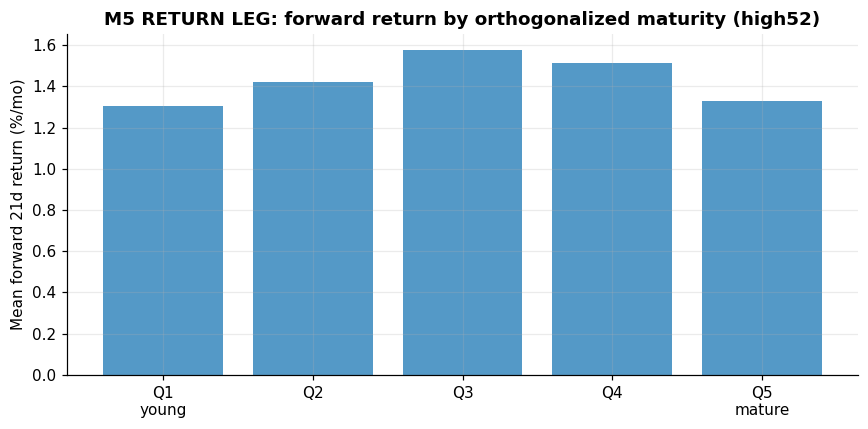

    -> m5_crash_leg_drawdown_2026-08-03.png


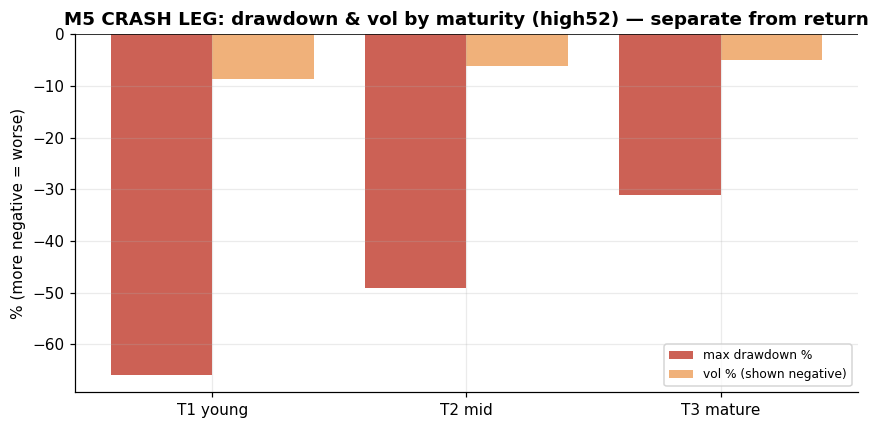

In [7]:
# =============================================================================
# M5 CELL 5 — PLOTS + SUMMARY (legs kept visually separate)
# =============================================================================
print("="*78); print("M5 SUMMARY"); print("="*78)
print(f"  cumulative sub-test tally: {SUBTEST_TALLY} (M1:9 + M3:5 + M4:4 + M5:{SUBTEST_TALLY-18})")
print("\n  TWO LEGS, KEPT SEPARATE — do NOT merge into one metric:")
print("   RETURN LEG (Cell 3): after orthogonalizing maturity vs momentum, does")
print("     young-minus-mature forward return survive? Significance machinery applies.")
print("   CRASH LEG (Cell 4): drawdown/skew/crash-freq/vol by maturity tercile,")
print("     estimation-with-CIs. The contested aged=crash question — data speaks.")
print("\n  READ ORDER: high52 is the HEADLINE for both legs; the two MA-age proxies")
print("  are robustness, reported side by side, NOT promoted if they look better.")
print("  Fill decision/insight/incidental by hand — and remember a crash-avoidance")
print("  benefit can be REAL even if the return leg is null (that's why separate).")

# return-leg quintile plot (headline proxy)
try:
    qs_h,_=return_leg("high52")
    fig,ax=plt.subplots(figsize=(8,4))
    qmeans=[np.nanmean(qs_h[q])*100 for q in range(1,N_QUINTILES+1)]
    ax.bar(range(1,N_QUINTILES+1),qmeans,color="#2980b9",alpha=0.8)
    ax.set_xticks(range(1,N_QUINTILES+1))
    ax.set_xticklabels(["Q1\nyoung","Q2","Q3","Q4","Q5\nmature"])
    ax.set_ylabel("Mean forward 21d return (%/mo)")
    ax.set_title("M5 RETURN LEG: forward return by orthogonalized maturity (high52)",weight="bold")
    save_fig(fig,"m5_return_leg_quintiles"); plt.show()
except Exception as e:
    print(f"  (return-leg plot skipped: {e})")

# crash-leg drawdown plot (headline proxy)
try:
    ts_h=crash_leg("high52")
    fig,ax=plt.subplots(figsize=(8,4))
    dds=[max_drawdown(ts_h[tc])*100 for tc in (1,2,3)]
    vols=[np.nanstd(ts_h[tc][~np.isnan(ts_h[tc])],ddof=1)*100 for tc in (1,2,3)]
    x=np.arange(3)
    ax.bar(x-0.2,dds,0.4,label="max drawdown %",color="#c0392b",alpha=0.8)
    ax.bar(x+0.2,[-v for v in vols],0.4,label="vol % (shown negative)",color="#e67e22",alpha=0.6)
    ax.set_xticks(x); ax.set_xticklabels(["T1 young","T2 mid","T3 mature"])
    ax.set_ylabel("% (more negative = worse)")
    ax.set_title("M5 CRASH LEG: drawdown & vol by maturity (high52) — separate from return",weight="bold")
    ax.legend(fontsize=8); ax.axhline(0,color="black",lw=0.5)
    save_fig(fig,"m5_crash_leg_drawdown"); plt.show()
except Exception as e:
    print(f"  (crash-leg plot skipped: {e})")

---
## After running

**Read the two legs separately — do not merge them.**
- **Return leg:** did young-minus-mature survive orthogonalization, and is it
  significant? (Watch for it collapsing to ~0 — that would mean maturity was just
  momentum.)
- **Crash leg:** does drawdown/skew differ by maturity, and does the vol column
  show whether any difference is crash-avoidance vs just being calmer? The
  crowding→crash story is contested — let the numbers speak.

Share: validation block (**especially the residual-correlation proof**), the
return-leg quintile table + spread with CI, the crash-leg table (all four metrics
by tercile, with CIs) for the headline and both robustness proxies, and both
plots.

**A null return leg with a real crash-leg difference is a valid, interesting
outcome** — that's exactly why the legs are separate. Writes to
`hypotheses/momentum/enhancements_M5_<date>/`; nothing frozen is touched.